# Chapitre 9 - Exercices 9.1 à 9.5

Ce notebook traite les premiers exercices du chapitre 9, consacrés à la
linéarisabilité :

- **9.1** : linéarisable ou pas ? Quatre historiques à juger (raisonnement) ;
- **9.2** : le coût d'un vérificateur de linéarisabilité, avec et sans mémoïsation
  (mini-lab) ;
- **9.3** : quorums, délais variables et réparation synchrone (mini-lab et calcul) ;
- **9.4** : placer le leader d'une base linéarisable répartie sur trois centres de
  données (calcul) ;
- **9.5** : linéarisable, sérialisable ou causal ? Et la course entre une notification
  et la réplication (raisonnement et calcul).

In [1]:
import itertools
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.consistency import Op
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## Exercice 9.1 : linéarisable ou pas ?

**Énoncé.** Un registre $x$ vaut initialement 0. Pour chacun des quatre historiques
suivants (intervalles [appel, réponse] en millisecondes), dire s'il est linéarisable ; si
oui, donner un ordre de linéarisation, sinon expliquer pourquoi aucun n'existe.

- **(a)** A : `write(1)` [0, 4] ; B : `write(2)` [1, 3] ; C : `read → 2` [5, 6] ; C : `read → 1` [7, 8].
- **(b)** A : `cas(0 → 1) ok` [0, 2] ; B : `cas(0 → 2) ok` [1, 3].
- **(c)** A : `write(1)` [0, ∞[ sans réponse (délai expiré) ; B : `read → 0` [2, 3] ; C : `read → 1` [4, 5].
- **(d)** A : `write(1)` [0, 1] ; B : `read → 0` [0,5 ; 3] ; C : `read → 1` [2 ; 2,5].

Vérifier ensuite les réponses avec `cs.check_linearizable`.

**Rappels.** Définition par points de linéarisation, lectures concurrentes d'une écriture,
opérations sans réponse (cours 1, section 2 ; section *What Makes a System Linearizable?*).

**Solution.**

- **(a) Non.** Les deux écritures sont terminées à $t = 4$, avant les deux lectures de C,
  qui sont séquentielles. Après les deux écritures, la valeur est fixée (1 ou 2 selon
  l'ordre des points) et plus personne n'écrit : deux lectures successives ne peuvent pas
  renvoyer 2 puis 1.
- **(b) Non.** Les deux CAS attendent 0 et réussissent. Quel que soit l'ordre, le second
  trouve la valeur écrite par le premier (1 ou 2), pas 0 : il devrait échouer.
- **(c) Oui.** Une écriture sans réponse a pu prendre effet à n'importe quel instant après
  son appel (ou jamais). Ordre : lecture de B (0), puis l'écriture de A, placée après le
  point de B et avant 5, puis la lecture de C (1).
- **(d) Oui, et c'est le piège.** B lit 0 alors que l'écriture de 1 est **terminée** avant
  la fin de B, et que C a même lu 1 **pendant** la lecture de B. Mais B a commencé à 0,5,
  avant la fin de l'écriture : on place par exemple le point de B à 0,55, celui de
  l'écriture à 0,7, et celui de C à 2,2 (le vérificateur choisit 0,88 pour les deux
  premiers, B passant en premier). Les lectures concurrentes ont droit à l'ancienne valeur tant que leur
  point peut précéder celui de l'écriture.

,historique,linéarisable,ordre
0,(a),False,-
1,(b),False,-
2,(c),True,B:r→0@2.15 ; A:w(1)@2.15 ; C:r→1@4.15
3,(d),True,B:r→0@0.88 ; A:w(1)@0.88 ; C:r→1@2.08


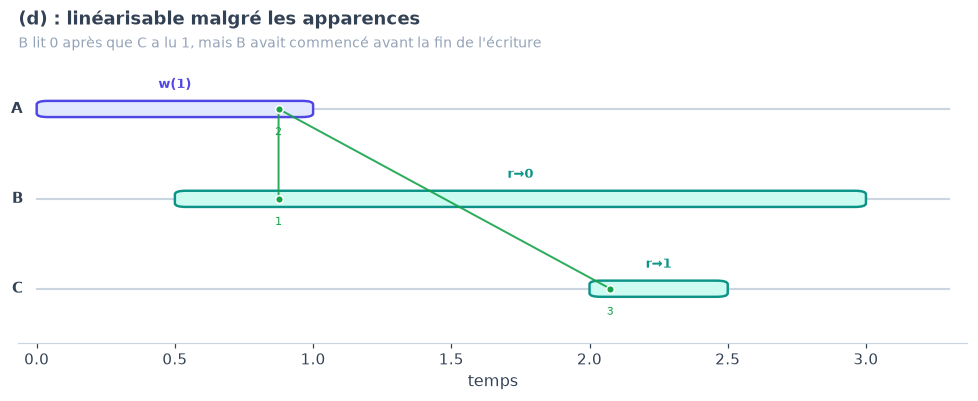

In [2]:
cas_ex = {
    "(a)": [Op("A", "write", 1, "ok", 0, 4), Op("B", "write", 2, "ok", 1, 3), Op("C", "read", None, 2, 5, 6),
            Op("C", "read", None, 1, 7, 8)],
    "(b)": [Op("A", "cas", (0, 1), True, 0, 2), Op("B", "cas", (0, 2), True, 1, 3)],
    "(c)": [Op("A", "write", 1, None, 0, done=False), Op("B", "read", None, 0, 2, 3), Op("C", "read", None, 1, 4, 5)],
    "(d)": [Op("A", "write", 1, "ok", 0, 1), Op("B", "read", None, 0, 0.5, 3), Op("C", "read", None, 1, 2, 2.5)],
}
rows = []
for k, h in cas_ex.items():
    r = cs.check_linearizable(h)
    rows.append(dict(historique=k, linéarisable=r.ok,
                     ordre=" ; ".join(f"{h[i].client}:{cs.op_label(h[i])}@{p:.2f}" for i, p in zip(r.order, r.points)) if r.ok else "-"))
display(pd.DataFrame(rows))
r = cs.check_linearizable(cas_ex["(d)"])
st = cs.plot_history(cas_ex["(d)"], title="(d) : linéarisable malgré les apparences",
                     subtitle="B lit 0 après que C a lu 1, mais B avait commencé avant la fin de l'écriture",
                     result=r, clients=["A", "B", "C"], t_max=3.3, width=9)
st.show()

Le vérificateur confirme (a) et (b) non linéarisables, (c) et (d) linéarisables. Dans (d),
l'ordre trouvé place la lecture de B **avant** l'écriture : le fait que B **réponde** tard
n'oblige pas son point à être tardif.

> **À retenir.** Juger la linéarisabilité, c'est chercher des points dans les
> intervalles. Une opération longue ou sans réponse offre beaucoup de latitude ; une
> opération **terminée** avant le début d'une autre la précède forcément.